# Clinical Data Analysis: Depression vs. Fatigue Severity

Exploratory and statistical analysis of a 1,000-record patient dataset (16 variables) covering ME/CFS, depression, and mixed diagnoses.

**Research question:** Is depression severity (PHQ-9) associated with fatigue severity (Fatigue Severity Scale)?

## 1. Load and inspect the data

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_csv("data/DATASET.csv")
print(df.shape)
df.info()
df.head()

(1000, 16)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   age                           1000 non-null   int64  
 1   gender                        1000 non-null   str    
 2   sleep_quality_index           953 non-null    float64
 3   brain_fog_level               952 non-null    float64
 4   physical_pain_score           966 non-null    float64
 5   stress_level                  952 non-null    float64
 6   depression_phq9_score         978 non-null    float64
 7   fatigue_severity_scale_score  979 non-null    float64
 8   pem_duration_hours            976 non-null    float64
 9   hours_of_sleep_per_night      979 non-null    float64
 10  pem_present                   1000 non-null   int64  
 11  work_status                   953 non-null    str    
 12  social_activity_level         960 non-null    str    
 13  exer

,age,gender,sleep_quality_index,brain_fog_level,physical_pain_score,stress_level,depression_phq9_score,fatigue_severity_scale_score,pem_duration_hours,hours_of_sleep_per_night,pem_present,work_status,social_activity_level,exercise_frequency,meditation_or_mindfulness,diagnosis
0,56,Male,8.7,3.9,9.2,8.1,10.0,6.5,9.0,7.7,0,Working,Low,Daily,Yes,Depression
1,69,Male,1.3,9.9,4.2,9.9,20.0,7.0,41.0,8.4,1,Working,Low,Often,Yes,Both
2,46,Female,4.0,5.4,4.8,NaN,24.0,1.6,13.0,6.9,0,Partially working,NaN,Rarely,Yes,Depression
3,32,Female,9.4,2.1,2.9,3.8,10.0,6.8,11.0,7.5,0,Not working,High,Never,Yes,Depression
4,60,Female,7.6,7.5,6.4,8.5,17.0,7.0,46.0,3.1,1,Not working,Low,Rarely,No,Both


## 2. Data quality assessment
Completeness, validity and consistency checks.

In [2]:
df.describe()

,age,sleep_quality_index,brain_fog_level,physical_pain_score,stress_level,depression_phq9_score,fatigue_severity_scale_score,pem_duration_hours,hours_of_sleep_per_night,pem_present
count,1000.000000,953.000000,952.000000,966.000000,952.000000,978.000000,979.000000,976.000000,979.000000,1000.000000
mean,44.385000,5.468625,5.611765,5.521843,5.459139,12.268916,6.407252,23.105533,6.571297,0.599000
std,15.321669,2.571423,2.649316,2.565460,2.566536,6.306588,2.206937,13.823953,2.040320,0.490346
min,18.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,3.000000,0.000000
25%,31.750000,3.100000,3.300000,3.325000,3.300000,9.000000,6.300000,11.000000,4.800000,0.000000
50%,45.000000,5.600000,5.800000,5.600000,5.400000,10.000000,7.000000,23.000000,6.600000,1.000000
75%,57.000000,7.700000,7.900000,7.800000,7.700000,16.000000,7.500000,35.000000,8.350000,1.000000
max,70.000000,10.000000,10.000000,10.000000,10.000000,27.000000,10.000000,47.000000,10.000000,1.000000


In [3]:
# Missing values per column
df.isnull().sum()

age                              0
gender                           0
sleep_quality_index             47
brain_fog_level                 48
physical_pain_score             34
stress_level                    48
depression_phq9_score           22
fatigue_severity_scale_score    21
pem_duration_hours              24
hours_of_sleep_per_night        21
pem_present                      0
work_status                     47
social_activity_level           40
exercise_frequency              39
meditation_or_mindfulness       11
diagnosis                        0
dtype: int64

In [4]:
# Categorical distributions
for col in ["diagnosis", "gender", "work_status"]:
    print(df[col].value_counts(dropna=False), "\n")

diagnosis
Depression    401
ME/CFS        397
Both          202
Name: count, dtype: int64 

gender
Male      524
Female    476
Name: count, dtype: int64 

work_status
Partially working    335
Working              320
Not working          298
NaN                   47
Name: count, dtype: int64 



In [5]:
numeric_cols = ["age", "sleep_quality_index", "brain_fog_level", "physical_pain_score",
                "stress_level", "depression_phq9_score", "fatigue_severity_scale_score",
                "pem_duration_hours", "hours_of_sleep_per_night"]

# Range check for each numeric variable
pd.DataFrame({"min": df[numeric_cols].min(), "max": df[numeric_cols].max(), "mean": df[numeric_cols].mean().round(2)})

,min,max,mean
age,18.0,70.0,44.38
sleep_quality_index,1.0,10.0,5.47
brain_fog_level,1.0,10.0,5.61
physical_pain_score,1.0,10.0,5.52
stress_level,1.0,10.0,5.46
depression_phq9_score,0.0,27.0,12.27
fatigue_severity_scale_score,0.0,10.0,6.41
pem_duration_hours,0.0,47.0,23.11
hours_of_sleep_per_night,3.0,10.0,6.57


## 3. Correlation analysis

In [6]:
main_vars = ["stress_level", "hours_of_sleep_per_night", "diagnosis", "gender",
             "depression_phq9_score", "age", "fatigue_severity_scale_score"]
df_main = df[main_vars]

# Drop rows missing either variable of interest
df_pair = df_main.dropna(subset=["depression_phq9_score", "fatigue_severity_scale_score"])
x = df_pair["depression_phq9_score"]
y = df_pair["fatigue_severity_scale_score"]

r, p = stats.pearsonr(x, y)
print(f"Pearson r = {r:.2f}, p = {p:.3g}, n = {len(df_pair)}")

Pearson r = -0.20, p = 7.73e-10, n = 957


## 4. Group comparisons

In [7]:
df_main.pivot_table(index="diagnosis",
                    values=["depression_phq9_score", "fatigue_severity_scale_score"],
                    aggfunc=["count", "mean", "std"]).round(2)

count                               \
           depression_phq9_score fatigue_severity_scale_score   
diagnosis                                                       
Both                         199                          200   
Depression                   390                          393   
ME/CFS                       389                          386   

                            mean                               \
           depression_phq9_score fatigue_severity_scale_score   
diagnosis                                                       
Both                       16.35                         7.45   
Depression                 15.01                         4.81   
ME/CFS                      7.44                         7.49   

                             std                               
           depression_phq9_score fatigue_severity_scale_score  
diagnosis                                                      
Both                        5.98                         0.83  
Depression                  5.92                         2.61  
ME/CFS                      2.70                         0.87

In [8]:
pd.crosstab(df_main["diagnosis"], df_main["gender"])

gender,Female,Male
diagnosis,,
Both,101,101
Depression,189,212
ME/CFS,186,211


## 5. Visualisation

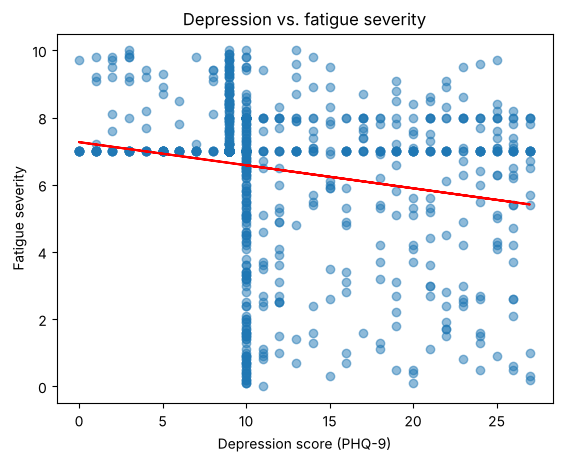

In [9]:
import os
os.makedirs("images", exist_ok=True)

slope, intercept = np.polyfit(x, y, 1)
plt.scatter(x, y, alpha=0.5)
plt.plot(x, slope * x + intercept, color="red")
plt.xlabel("Depression score (PHQ-9)")
plt.ylabel("Fatigue severity")
plt.title("Depression vs. fatigue severity")
plt.savefig("images/scatter.png", dpi=150, bbox_inches="tight")
plt.show()

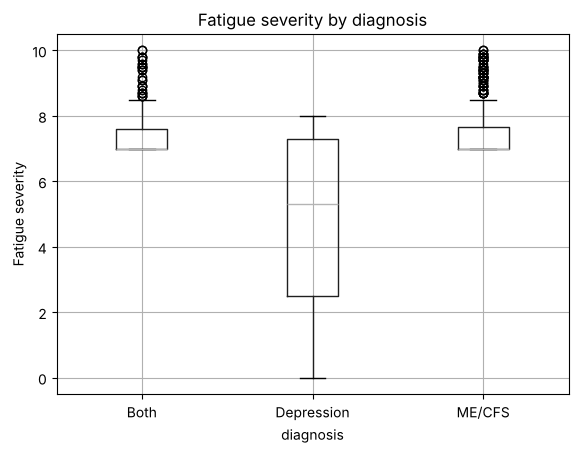

In [10]:
df_main.boxplot(column="fatigue_severity_scale_score", by="diagnosis")
plt.title("Fatigue severity by diagnosis")
plt.suptitle("")
plt.ylabel("Fatigue severity")
plt.savefig("images/boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Conclusion
- Across all patients, depression and fatigue show only a **weak negative correlation** (Pearson r ≈ −0.20, p < 0.001, n = 957). The original hypothesis of a strong positive link is **not supported**.
- The pattern is driven by diagnosis: ME/CFS patients have high fatigue but low depression scores (means 7.5 and 7.4), while depression patients have high depression but lower fatigue (15.0 and 4.8). Patients with **both** conditions score high on both (16.4 and 7.5).
- Depression and fatigue scores together separate the three diagnosis groups clearly, which makes them useful features for a future classification model.
- **Data quality note:** the scatter plot shows dense vertical and horizontal bands (PHQ-9 ≈ 9–10, fatigue = 7), which suggests imputed or default values and should be investigated before modelling.
- These results are correlational and do not imply causation.